
===== OPTIMIZED UNIVERSITY TIMETABLE =====
                 Course Faculty Group       Day        Time     Room
       Java Programming   Dr. F    G2    Monday  9:00-10:00 Room 102
            Mathematics   Dr. E    G1    Monday 11:00-12:00 Room 104
       Machine Learning   Dr. C    G2    Monday   1:00-2:00 Room 101
        Cloud Computing   Dr. C    G3    Monday   2:00-3:00 Room 102
      Operating Systems   Dr. C    G1    Monday   3:00-4:00 Room 104
Artificial Intelligence   Dr. A    G3   Tuesday  9:00-10:00 Room 102
  Computer Architecture   Dr. B    G3   Tuesday 10:00-11:00 Room 104
        Web Development   Dr. F    G3   Tuesday 11:00-12:00 Room 101
      Computer Networks   Dr. D    G1   Tuesday   1:00-2:00 Room 102
   Discrete Mathematics   Dr. E    G2   Tuesday   3:00-4:00 Room 101
             Statistics   Dr. E    G3 Wednesday 10:00-11:00 Room 101
     Python Programming   Dr. F    G1 Wednesday 10:00-11:00 Room 104
             Algorithms   Dr. A    G2 Wednesday 11:00-12:00

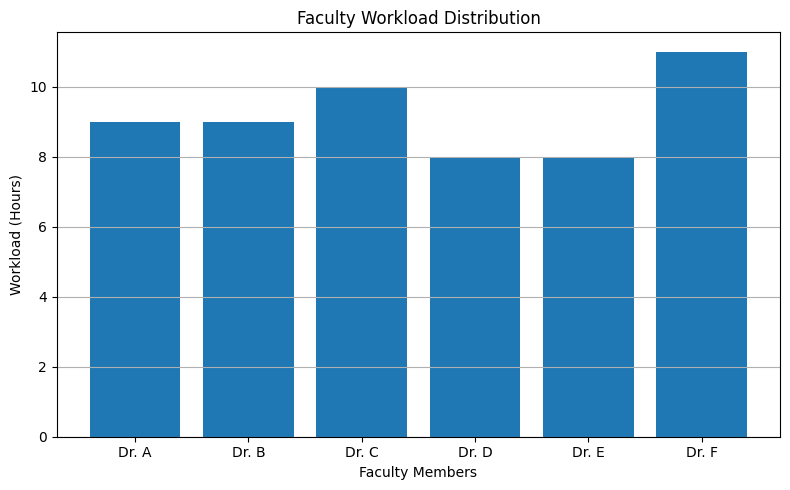


===== GENETIC ALGORITHM CONVERGENCE =====


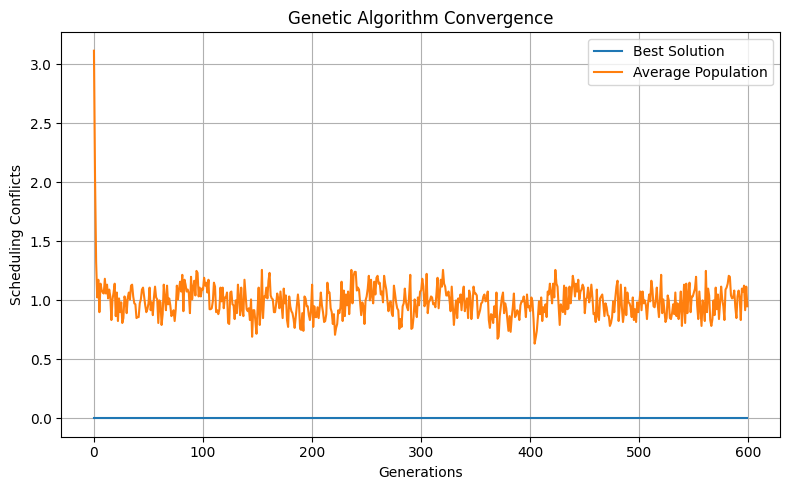

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

random.seed(42)
np.random.seed(42)

courses = [
    "Data Structures", "DBMS", "Operating Systems",
    "Computer Networks", "Mathematics", "Python Programming",
    "Algorithms", "Software Engineering", "Machine Learning",
    "Compiler Design", "Discrete Mathematics", "Java Programming",
    "Artificial Intelligence", "Computer Architecture",
    "Cloud Computing", "Cyber Security", "Statistics",
    "Web Development"
]

faculty = [
    "Dr. A", "Dr. B", "Dr. C", "Dr. D", "Dr. E", "Dr. F",
    "Dr. A", "Dr. B", "Dr. C", "Dr. D", "Dr. E", "Dr. F",
    "Dr. A", "Dr. B", "Dr. C", "Dr. D", "Dr. E", "Dr. F"
]

groups = ["G1"] * 6 + ["G2"] * 6 + ["G3"] * 6

duration = np.array([
    3, 2, 4, 3, 2, 4,
    4, 3, 3, 2, 4, 3,
    2, 4, 3, 3, 2, 4
])

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

time_slots = [
    "9:00-10:00", "10:00-11:00", "11:00-12:00",
    "1:00-2:00", "2:00-3:00", "3:00-4:00"
]

rooms = ["Room 101", "Room 102", "Room 103", "Room 104"]

n_courses = len(courses)
n_faculty = len(set(faculty))

POPULATION_SIZE = 120
GENERATIONS = 600
MUTATION_RATE = 0.08
CROSSOVER_RATE = 0.9
ELITE_SIZE = 5

def create_chromosome():
    return [
        [
            random.randrange(len(days)),
            random.randrange(len(time_slots)),
            random.randrange(len(rooms))
        ]
        for _ in range(n_courses)
    ]

def create_population():
    return [create_chromosome() for _ in range(POPULATION_SIZE)]

def calculate_conflicts(solution):

    conflicts = 0

    for i in range(n_courses):
        for j in range(i + 1, n_courses):

            if solution[i][0] == solution[j][0] and solution[i][1] == solution[j][1]:

                if solution[i][2] == solution[j][2]:
                    conflicts += 1

                if faculty[i] == faculty[j]:
                    conflicts += 1

                if groups[i] == groups[j]:
                    conflicts += 1

    return conflicts

def calculate_fitness(solution):
    return 1 / (1 + calculate_conflicts(solution))

def selection(population):
    contestants = random.sample(population, 5)
    return max(contestants, key=calculate_fitness)

def crossover(parent1, parent2):

    if random.random() < CROSSOVER_RATE:

        point = random.randint(1, n_courses - 1)

        child1 = parent1[:point] + parent2[point:]
        child2 = parent2[:point] + parent1[point:]

        return child1, child2

    return parent1[:], parent2[:]

def mutation(chromosome):

    chromosome = [gene[:] for gene in chromosome]

    for i in range(n_courses):

        if random.random() < MUTATION_RATE:

            chromosome[i] = [
                random.randrange(len(days)),
                random.randrange(len(time_slots)),
                random.randrange(len(rooms))
            ]

    return chromosome

best_solution = None
best_cost = float('inf')

best_history = []
average_history = []

population = create_population()

for generation in range(GENERATIONS):

    costs = [calculate_conflicts(ind) for ind in population]

    current_best_index = np.argmin(costs)
    current_best = population[current_best_index]
    current_cost = costs[current_best_index]

    if current_cost < best_cost:
        best_cost = current_cost
        best_solution = [gene[:] for gene in current_best]

    best_history.append(best_cost)
    average_history.append(np.mean(costs))

    population.sort(key=calculate_fitness, reverse=True)

    new_population = [
        [gene[:] for gene in individual]
        for individual in population[:ELITE_SIZE]
    ]

    while len(new_population) < POPULATION_SIZE:

        parent1 = selection(population)
        parent2 = selection(population)

        child1, child2 = crossover(parent1, parent2)

        child1 = mutation(child1)
        child2 = mutation(child2)

        new_population.append(child1)

        if len(new_population) < POPULATION_SIZE:
            new_population.append(child2)

    population = new_population

print("\n===== OPTIMIZED UNIVERSITY TIMETABLE =====")

schedule = []

for i in range(n_courses):

    day, slot, room = best_solution[i]

    schedule.append([
        courses[i],
        faculty[i],
        groups[i],
        days[day],
        time_slots[slot],
        rooms[room]
    ])

df = pd.DataFrame(schedule, columns=[
    "Course", "Faculty", "Group", "Day", "Time", "Room"
])

df["Day"] = pd.Categorical(df["Day"], categories=days, ordered=True)
df["Time"] = pd.Categorical(df["Time"], categories=time_slots, ordered=True)

df = df.sort_values(["Day", "Time", "Room"])

print(df.to_string(index=False))

print("\n===== FACULTY WORKLOAD =====")

workload = np.zeros(n_faculty)
faculty_names = sorted(set(faculty))

for i in range(n_courses):
    index = faculty_names.index(faculty[i])
    workload[index] += duration[i]

for i in range(n_faculty):
    print(
        faculty_names[i],
        "->",
        workload[i],
        "hours"
    )

print("\n===== FINAL RESULTS =====")
print("Total Courses:", n_courses)
print("Population Size:", POPULATION_SIZE)
print("Generations:", GENERATIONS)
print("Mutation Rate:", MUTATION_RATE)
print("Crossover Rate:", CROSSOVER_RATE)
print("Minimum Conflicts:", best_cost)
print("Fitness Score:", round(calculate_fitness(best_solution), 4))

if best_cost == 0:
    print("Status: Conflict-free timetable generated")
else:
    print("Status: Best timetable generated with remaining conflicts")

print("\n===== FACULTY WORKLOAD DISTRIBUTION =====")

plt.figure(figsize=(8, 5))

plt.bar(faculty_names, workload)

plt.xlabel("Faculty Members")
plt.ylabel("Workload (Hours)")
plt.title("Faculty Workload Distribution")

plt.grid(axis="y")
plt.tight_layout()
plt.show()

print("\n===== GENETIC ALGORITHM CONVERGENCE =====")

plt.figure(figsize=(8, 5))

plt.plot(best_history, label="Best Solution")
plt.plot(average_history, label="Average Population")

plt.xlabel("Generations")
plt.ylabel("Scheduling Conflicts")
plt.title("Genetic Algorithm Convergence")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
